In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md
from scipy.ndimage import gaussian_filter
import os

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "Times New Roman",
    "font.serif": ["Arial"],  # or other preferred serif font
    "mathtext.fontset": "cm",            # Computer Modern for math text
    "text.usetex": False,                 # Use LaTeX for text rendering]
    "pdf.fonttype": 42,                 # Use LaTeX for text rendering

    # Figure
    "figure.figsize": (6, 4),            # width, height in inches
    "figure.dpi": 150,                   # medium resolution

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,                   # optional, remove if you want no grid
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

# --- Utility functions ---
def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

def load_pf_data(protein, model_name, ensemble_dir="MD_DATA", exp_dir="EXP_DATA/PF_Nguyen_2018"):
    exp = pd.read_csv(f"../../{exp_dir}/{protein}.csv")
    residues = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/exp_residues.txt")
    try:
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_rew_lnPF.txt"))
    except:
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/rew_lnPF.txt"))
    priorPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/prior_lnPF.txt"))
    try:
        stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_stats_df.csv")
    except:
        stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/stats_df.csv")
    try:
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_reweighting_chi2_phi_theta.txt")
    except:
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/reweighting_chi2_phi_theta.txt")
    chi2, phi, thetas = rewdata[0, :], rewdata[1, :], rewdata[2, :]
    idxs = [list(exp["Model_residue"]).index(ele) for ele in residues]
    return exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]



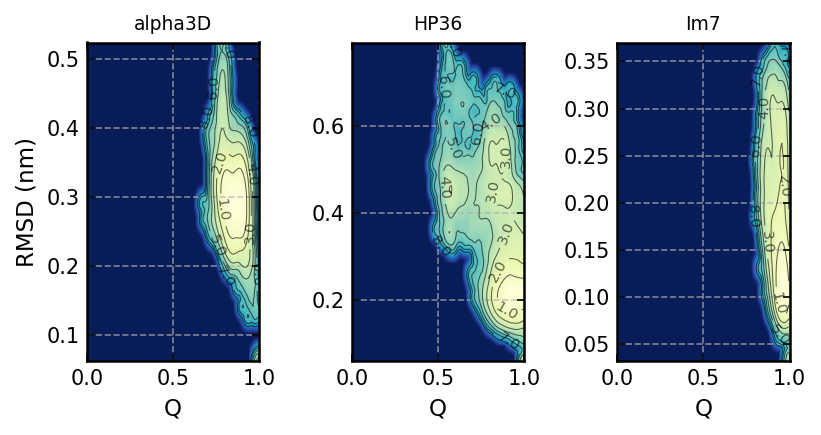

In [7]:
# plotting only the prior landscapes with RMSD vs Q

ensemble_dir = 'MD_DATA'
proteins = ['alpha3D', 'HP36', 'Im7']

ncols = 5
nrows = int(np.ceil(len(proteins) / ncols))

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(9, 3), sharex=True, sharey=False)
axes = axes.flatten()

for i, protein in enumerate(proteins):
    ax = axes[i]

    ntrajs = len(find_xtc_filenames(f"../../{ensemble_dir}/{protein}/"))
    trajs = np.array(sorted(list(np.arange(1,ntrajs+1).astype(str)))).astype(int)

    for t in trajs:
        Q = np.loadtxt(f"../../{ensemble_dir}/{protein}/native_contacts/Q{t}.txt")
        rmsd = np.loadtxt(f"../../{ensemble_dir}/{protein}/sim{t}/rmsd_BB.xvg", skiprows=18)[:, 1]
        if t == 1:
            Q_all, rmsd_all = Q, rmsd
        else:
            Q_all = np.concatenate((Q_all, Q))
            rmsd_all = np.concatenate((rmsd_all, rmsd))

    kT = 298 * 0.008314
    bins = (100, 100)
    smooth_sigma = 1.2
    pseudocount = 1e-12

    H, Q_edges, rmsd_edges = np.histogram2d(Q_all, rmsd_all, bins=bins, range=[[0, 1], [rmsd_all.min(), rmsd_all.max()]])
    P = H / np.sum(H)
    P_smooth = gaussian_filter(P, sigma=smooth_sigma)
    F = -kT * np.log(P_smooth + pseudocount) * 0.239005736
    F -= np.min(F)

    Q_centers = 0.5 * (Q_edges[:-1] + Q_edges[1:])
    rmsd_centers = 0.5 * (rmsd_edges[:-1] + rmsd_edges[1:])

    im = ax.imshow(F.T, origin='lower', extent=[0, 1, rmsd_centers.min(), rmsd_centers.max()], aspect='auto', cmap='YlGnBu', interpolation='bilinear')

    levels = np.linspace(np.min(F), np.min(F) + 8, 9)
    cs = ax.contour(Q_centers, rmsd_centers, F.T, levels=levels, colors='k', linewidths=0.5, alpha=0.6)
    ax.clabel(cs, inline=True, fontsize=7, fmt='%.1f')

    ax.set_xlim(0, 1)
    ax.set_title(protein, fontsize=9)

    if i // ncols == nrows - 1:
        ax.set_xlabel('Q', fontsize=11)
    if i % ncols == 0:
        ax.set_ylabel('RMSD (nm)', fontsize=11)

for i in range(len(proteins), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.savefig("2D_folding_FELs_prior_rmsd_Q.png", dpi=200, bbox_inches="tight")

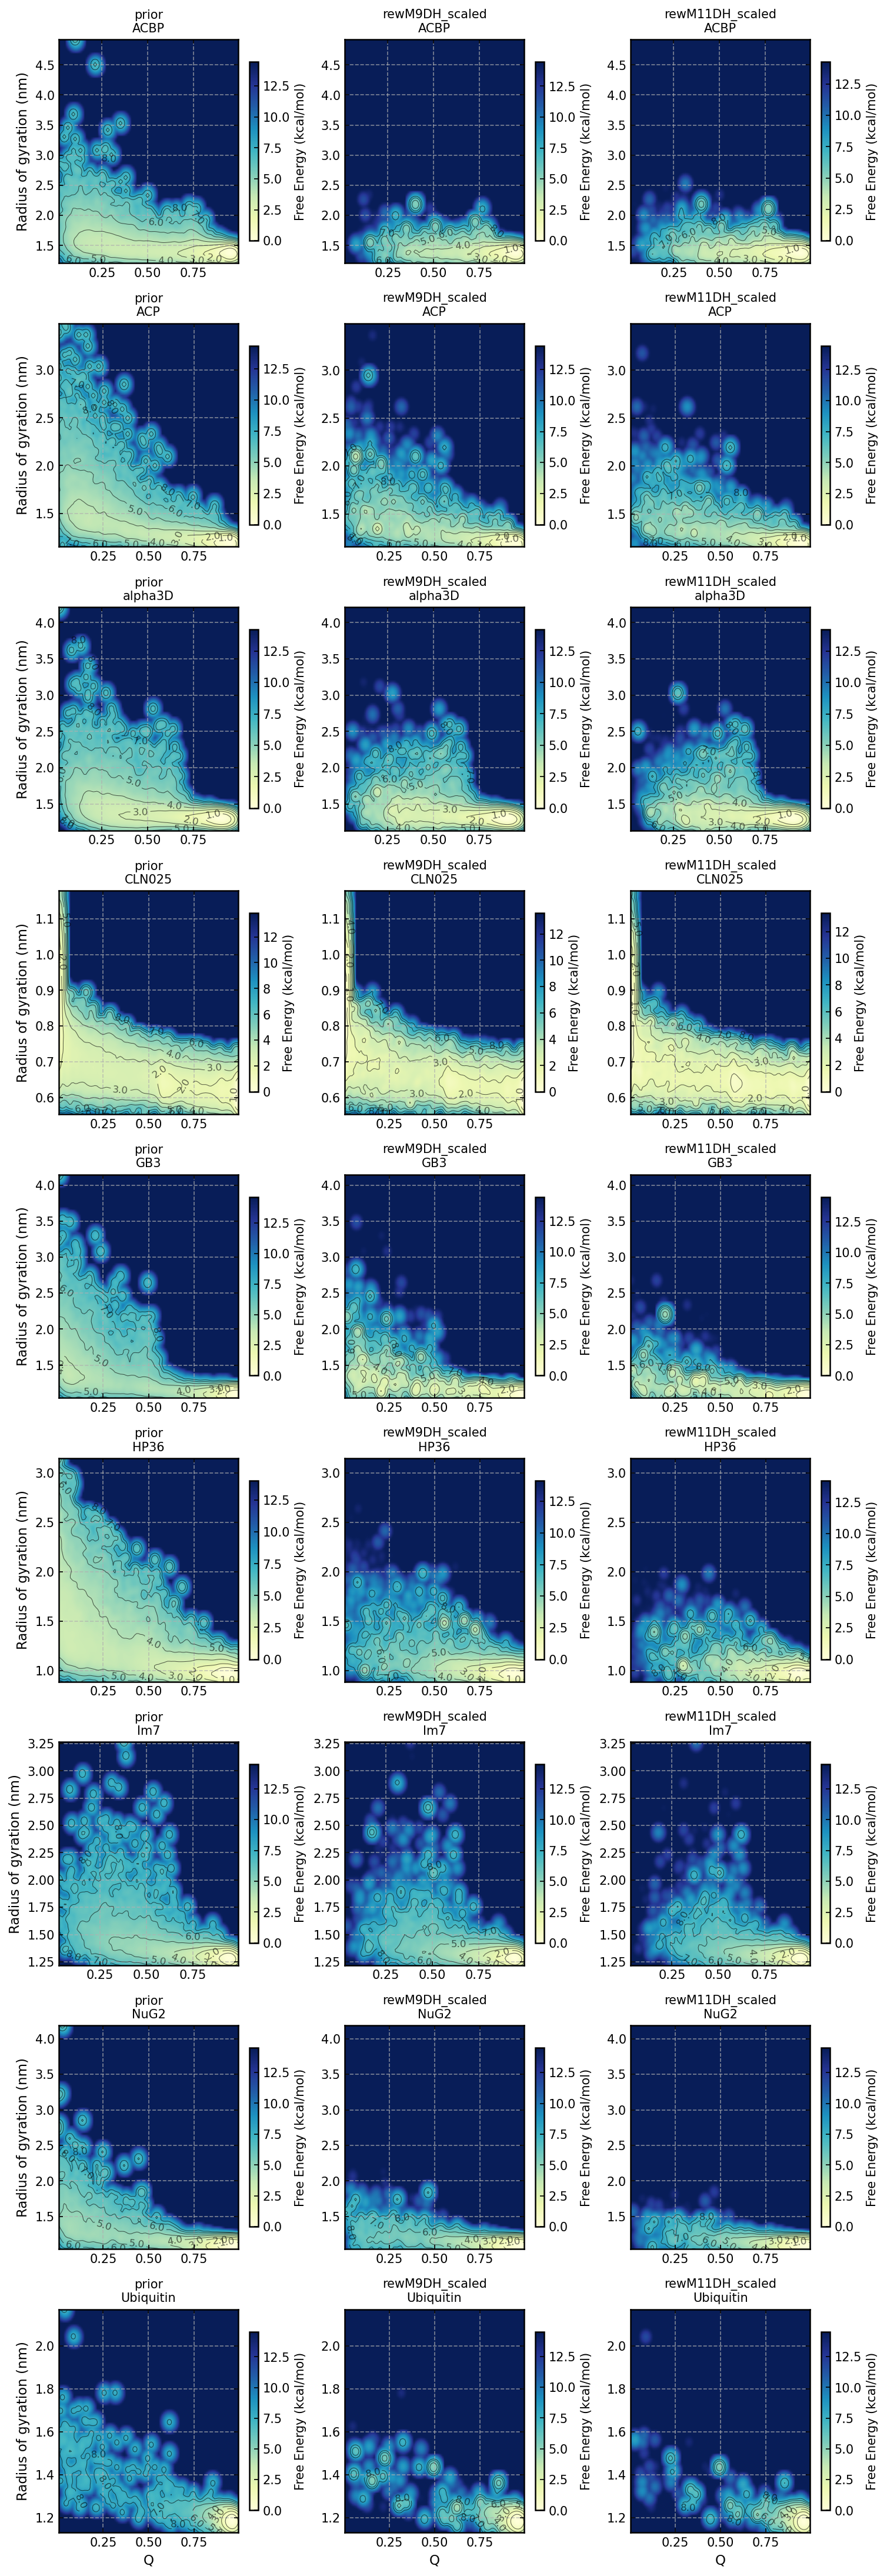

In [ ]:


models = ['prior','rewM9DH_scaled', 'rewM11DH_scaled']  
ensemble_dir = 'BIOEMU_DATA'
proteins = ['ACBP', 'ACP', 'alpha3D', 'CLN025', 'GB3', 'HP36', 'Im7', 'NuG2' ,'Ubiquitin']


# create figure WITHOUT shared axes (as requested)
fig, axes = plt.subplots(
    nrows=len(proteins),
    ncols=len(models),
    figsize=(3.5 * len(models), 3.5 * len(proteins))
)

for i, protein in enumerate(proteins):
    for j, model in enumerate(models):
        ax = axes[i, j]

        ntrajs = len(find_xtc_filenames(f"../../{ensemble_dir}/{protein}/"))
        # get correct traj order
        trajs = np.array(sorted(list(np.arange(ntrajs).astype(str)))).astype(int)

        if model != 'prior':
            # Load data
            wopt = np.load(f"../../{ensemble_dir}/{protein}/{model}/wopt.npy")
            for t in trajs:
                try:
                    frames = np.loadtxt(f"../../{ensemble_dir}/{protein}/rewM10/okframes_traj{t}.txt").astype(int)
                    Q = np.loadtxt(f"../../{ensemble_dir}/{protein}/native_contacts/Q{t}.txt")[frames]
                    rg = np.loadtxt(f"../../{ensemble_dir}/{protein}/rg_data/rg_traj{t}.txt")[frames]
                except:
                    Q = np.loadtxt(f"../../{ensemble_dir}/{protein}/native_contacts/Q{t}.txt")
                    rg = np.loadtxt(f"../../{ensemble_dir}/{protein}/rg_data/rg_traj{t}.txt")
                if t == 0:
                    Q_all, rg_all = Q, rg
                else:
                    Q_all = np.concatenate((Q_all, Q))
                    rg_all = np.concatenate((rg_all, rg))

            # Compute FEL
            kT = 298 * 0.008314
            bins = (100, 100)
            smooth_sigma = 1.2
            pseudocount = 1e-12
            H, Q_edges, Rg_edges = np.histogram2d(Q_all, rg_all, weights=wopt, bins=bins)
            P = H / np.sum(H)
            P_smooth = gaussian_filter(P, sigma=smooth_sigma)
            F = -kT * np.log(P_smooth + pseudocount) * 0.239005736  # kcal/mol
            F -= np.min(F)

        else:
            # Load data (no weights)
            for t in trajs:
                Q = np.loadtxt(f"../../{ensemble_dir}/{protein}/native_contacts/Q{t}.txt")
                rg = np.loadtxt(f"../../{ensemble_dir}/{protein}/rg_data/rg_traj{t}.txt")
                if t == 0:
                    Q_all, rg_all = Q, rg
                else:
                    Q_all = np.concatenate((Q_all, Q))
                    rg_all = np.concatenate((rg_all, rg))

            # Compute FEL
            kT = 298 * 0.008314
            bins = (100, 100)
            smooth_sigma = 1.2
            pseudocount = 1e-12
            H, Q_edges, Rg_edges = np.histogram2d(Q_all, rg_all, bins=bins)
            P = H / np.sum(H)
            P_smooth = gaussian_filter(P, sigma=smooth_sigma)
            F = -kT * np.log(P_smooth + pseudocount) * 0.239005736
            F -= np.min(F)

        # Plot FEL
        Q_centers = 0.5 * (Q_edges[:-1] + Q_edges[1:])
        Rg_centers = 0.5 * (Rg_edges[:-1] + Rg_edges[1:])
        im = ax.imshow(
            F.T,
            origin='lower',
            extent=[Q_centers.min(), Q_centers.max(), Rg_centers.min(), Rg_centers.max()],
            aspect='auto',
            cmap='YlGnBu',
            interpolation='bilinear'
        )

        # Contours
        levels = np.linspace(np.min(F), np.min(F) + 8, 9)
        cs = ax.contour(Q_centers, Rg_centers, F.T, levels=levels, colors='k', linewidths=0.5, alpha=0.6)
        ax.clabel(cs, inline=True, fontsize=8, fmt='%.1f')

        # Labels and formatting
        if i == len(proteins) - 1:
            ax.set_xlabel('Q', fontsize=11)
        if j == 0:
            ax.set_ylabel('Radius of gyration (nm)', fontsize=11)

        # Title includes both model and protein name
        ax.set_title(f'{model}\n{protein}', fontsize=10)

        cbar = fig.colorbar(im, ax=ax, shrink=0.8)
        cbar.set_label('Free Energy (kcal/mol)', fontsize=10)

plt.tight_layout(rect=[0.04, 0.04, 1, 0.97])
plt.savefig("2D_folding_FELs_allmodels.png", dpi=200, bbox_inches="tight")


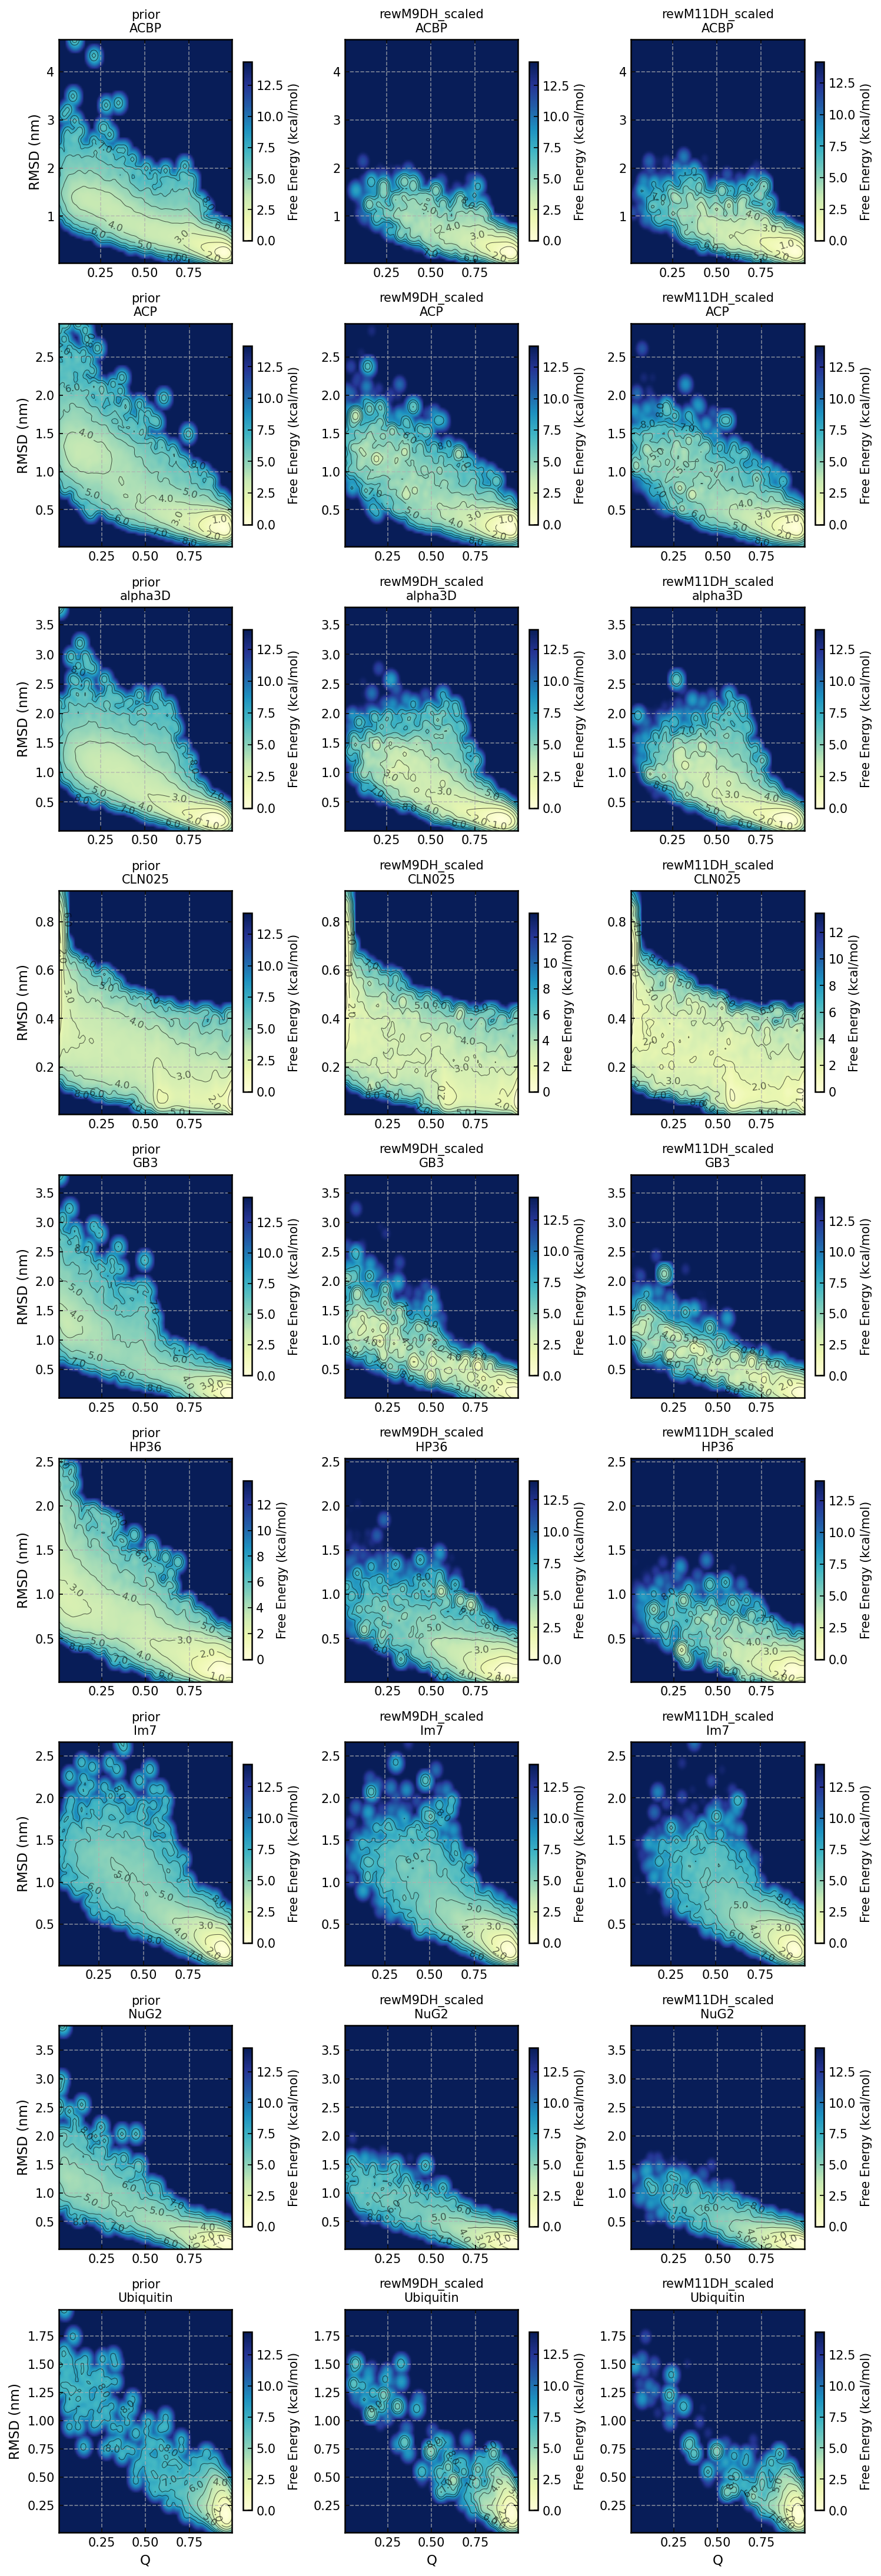

In [8]:

# plotting the same but with rmsd
models = ['prior','rewM9DH_scaled', 'rewM11DH_scaled']  
ensemble_dir = 'BIOEMU_DATA'
proteins = ['ACBP', 'ACP', 'alpha3D', 'CLN025', 'GB3', 'HP36', 'Im7', 'NuG2' ,'Ubiquitin']


# create figure WITHOUT shared axes (as requested)
fig, axes = plt.subplots(
    nrows=len(proteins),
    ncols=len(models),
    figsize=(3.5 * len(models), 3.5 * len(proteins))
)

for i, protein in enumerate(proteins):
    for j, model in enumerate(models):
        ax = axes[i, j]

        ntrajs = len(find_xtc_filenames(f"../../{ensemble_dir}/{protein}/"))
        # get correct traj order
        trajs = np.array(sorted(list(np.arange(ntrajs).astype(str)))).astype(int)

        if model != 'prior':
            # Load data
            wopt = np.load(f"../../{ensemble_dir}/{protein}/{model}/wopt.npy")
            for t in trajs:
                try:
                    frames = np.loadtxt(f"../../{ensemble_dir}/{protein}/rewM10/okframes_traj{t}.txt").astype(int)
                    Q = np.loadtxt(f"../../{ensemble_dir}/{protein}/native_contacts/Q{t}.txt")[frames]
                    rmsd = np.loadtxt(f"../../{ensemble_dir}/{protein}/rmsd_data/rmsd_traj{t}.xtc.xvg", skiprows=18)[:,1][frames]
                except:
                    Q = np.loadtxt(f"../../{ensemble_dir}/{protein}/native_contacts/Q{t}.txt")
                    rmsd = np.loadtxt(f"../../{ensemble_dir}/{protein}/rmsd_data/rmsd_traj{t}.xtc.xvg", skiprows=18)[:,1]
                if t == 0:
                    Q_all, rmsd_all = Q, rmsd
                else:
                    Q_all = np.concatenate((Q_all, Q))
                    rmsd_all = np.concatenate((rmsd_all, rmsd))

            # Compute FEL
            kT = 298 * 0.008314
            bins = (100, 100)
            smooth_sigma = 1.2
            pseudocount = 1e-12
            H, Q_edges, Rg_edges = np.histogram2d(Q_all, rmsd_all, weights=wopt, bins=bins)
            P = H / np.sum(H)
            P_smooth = gaussian_filter(P, sigma=smooth_sigma)
            F = -kT * np.log(P_smooth + pseudocount) * 0.239005736  # kcal/mol
            F -= np.min(F)

        else:
            # Load data (no weights)
            for t in trajs:
                Q = np.loadtxt(f"../../{ensemble_dir}/{protein}/native_contacts/Q{t}.txt")
                rmsd = np.loadtxt(f"../../{ensemble_dir}/{protein}/rmsd_data/rmsd_traj{t}.xtc.xvg", skiprows=18)[:,1]
                if t == 0:
                    Q_all, rmsd_all = Q, rmsd
                else:
                    Q_all = np.concatenate((Q_all, Q))
                    rmsd_all = np.concatenate((rmsd_all, rmsd))

            # Compute FEL
            kT = 298 * 0.008314
            bins = (100, 100)
            smooth_sigma = 1.2
            pseudocount = 1e-12
            H, Q_edges, Rg_edges = np.histogram2d(Q_all, rmsd_all, bins=bins)
            P = H / np.sum(H)
            P_smooth = gaussian_filter(P, sigma=smooth_sigma)
            F = -kT * np.log(P_smooth + pseudocount) * 0.239005736
            F -= np.min(F)

        # Plot FEL
        Q_centers = 0.5 * (Q_edges[:-1] + Q_edges[1:])
        Rg_centers = 0.5 * (Rg_edges[:-1] + Rg_edges[1:])
        im = ax.imshow(
            F.T,
            origin='lower',
            extent=[Q_centers.min(), Q_centers.max(), Rg_centers.min(), Rg_centers.max()],
            aspect='auto',
            cmap='YlGnBu',
            interpolation='bilinear'
        )

        # Contours
        levels = np.linspace(np.min(F), np.min(F) + 8, 9)
        cs = ax.contour(Q_centers, Rg_centers, F.T, levels=levels, colors='k', linewidths=0.5, alpha=0.6)
        ax.clabel(cs, inline=True, fontsize=8, fmt='%.1f')

        # Labels and formatting
        if i == len(proteins) - 1:
            ax.set_xlabel('Q', fontsize=11)
        if j == 0:
            ax.set_ylabel('RMSD (nm)', fontsize=11)

        # Title includes both model and protein name
        ax.set_title(f'{model}\n{protein}', fontsize=10)

        cbar = fig.colorbar(im, ax=ax, shrink=0.8)
        cbar.set_label('Free Energy (kcal/mol)', fontsize=10)

plt.tight_layout(rect=[0.04, 0.04, 1, 0.97])
plt.savefig("2D_folding_FELs_allmodels_rmsd_Q.png", dpi=200, bbox_inches="tight")
